# Transcript localization in T cells across all breast Xenium slices

This notebook samples **T cells** from the combined pool of all
annotated spatial slices, then measures each selected marker transcript's
distance to its cell boundary. Distances are normalized by the radius of a
circle with the same area as the cell, making them comparable across cells.

The random seed and all input/output paths are defined below. Sampling is
performed over the pooled slices (rather than taking 500 cells per slice).

In [1]:
from pathlib import Path
import re

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from shapely.geometry import Point, Polygon
from tqdm.auto import tqdm

INTERIM_DIR = Path("/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/interim/spatial")
RAW_SPATIAL_DIR = Path("/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/spatial")
ANNOTATION_FILE = Path("/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/single-cell/41592_2026_3089_MOESM4_ESM.xlsx")
OUTPUT_DIR = Path("/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/spillover_localization")

N_TCELLS = 10_000
RANDOM_SEED = 20260926
TCELL_PATTERN = r"T"  # Retains the original notebook's definition.

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Marker-gene sets

In [2]:
gene_annot = pd.read_excel(ANNOTATION_FILE, sheet_name="ST 4", skiprows=1)

cancer_genes = set(
    gene_annot.loc[gene_annot["Annotation_DB"].eq("malignant cell"), "Genes"].dropna()
)
tcell_genes = set(
    gene_annot.loc[
        gene_annot["Annotation_DB"].fillna("").str.contains("T", regex=False), "Genes"
    ].dropna()
)

# Give T-cell markers precedence if the annotation contains an overlap.
cancer_genes -= tcell_genes
print(f"Tumor markers: {len(cancer_genes):,}; T-cell markers: {len(tcell_genes):,}")

Tumor markers: 32; T-cell markers: 33


## Find T cells in every annotated slice

The accession/sample prefix is shared by each annotated `.h5ad` file and its
raw transcript and cell-boundary parquet files. Cell IDs only need to be unique
within a slice, so `slice_id` is retained in every result table.

In [3]:
def slice_id_from_h5ad(path):
    suffix = "_rctd_annotated.h5ad"
    if not path.name.endswith(suffix):
        raise ValueError(f"Unexpected annotated filename: {path.name}")
    return path.name.removesuffix(suffix)


h5ad_files = sorted(INTERIM_DIR.glob("GSM950*_rctd_annotated.h5ad"))
if not h5ad_files:
    raise FileNotFoundError(f"No annotated slices found in {INTERIM_DIR}")

candidate_frames = []
slice_files = {}

for h5ad_path in tqdm(h5ad_files, desc="Reading slice annotations"):
    slice_id = slice_id_from_h5ad(h5ad_path)
    transcript_path = RAW_SPATIAL_DIR / f"{slice_id}_transcripts.parquet"
    boundary_path = RAW_SPATIAL_DIR / f"{slice_id}_cell_boundaries.parquet"
    missing = [p for p in (transcript_path, boundary_path) if not p.exists()]
    if missing:
        raise FileNotFoundError(f"Missing raw file(s) for {slice_id}: {missing}")

    adata = ad.read_h5ad(h5ad_path, backed="r")
    try:
        required = {"cell_id", "harmony_cell_type"}
        absent = required.difference(adata.obs.columns)
        if absent:
            raise KeyError(f"{h5ad_path.name} is missing obs columns: {sorted(absent)}")
        labels = adata.obs["harmony_cell_type"].astype("string")
        mask = labels.str.contains(TCELL_PATTERN, case=True, regex=True, na=False)
        candidates = pd.DataFrame({
            "slice_id": slice_id,
            "cell_id": adata.obs.loc[mask, "cell_id"].astype(str).to_numpy(),
            "cell_type": labels.loc[mask].astype(str).to_numpy(),
        }).drop_duplicates(["slice_id", "cell_id"])
        candidate_frames.append(candidates)
    finally:
        adata.file.close()

    slice_files[slice_id] = {
        "transcripts": transcript_path,
        "boundaries": boundary_path,
    }

tcell_candidates = pd.concat(candidate_frames, ignore_index=True)
counts_by_slice = tcell_candidates.groupby("slice_id").size().rename("available_tcells")
print(f"Found {len(tcell_candidates):,} candidate T cells in {len(h5ad_files)} slices")
display(counts_by_slice.to_frame())

Reading slice annotations:   0%|          | 0/19 [00:00<?, ?it/s]

Found 107,037 candidate T cells in 19 slices


,available_tcells
slice_id,
GSM9509156_breast_breast_B17_B17,2704
GSM9509157_breast_breast_B16_B16,3056
GSM9509158_breast_breast_B15_B15,1505
GSM9509159_breast_breast_B14_B14,3097
GSM9509160_breast_breast_B2_B2,2574
GSM9509161_breast_breast_B13_B13,1137
GSM9509162_breast_breast_B12_B12,8697
GSM9509163_breast_breast_B11_B11,5556
GSM9509164_breast_breast_B10_B10,5064


In [4]:
tcell_candidates['cell_type'].unique()

array(['natural T-regulatory cell', 'cytotoxic T cell',
       'CD4-positive, alpha-beta memory T cell'], dtype=object)

## Sample 500 T cells from the pooled candidates

In [5]:
if len(tcell_candidates) < N_TCELLS:
    raise ValueError(
        f"Requested {N_TCELLS} T cells, but only {len(tcell_candidates)} were found"
    )

sampled_cells = (
    tcell_candidates.sample(n=N_TCELLS, random_state=RANDOM_SEED, replace=False)
    .sort_values(["slice_id", "cell_id"])
    .reset_index(drop=True)
)

assert len(sampled_cells) == N_TCELLS
sampled_cells.to_csv(OUTPUT_DIR / "sampled_tcells.csv", index=False)

sample_qc = (
    counts_by_slice.to_frame()
    .join(sampled_cells.groupby("slice_id").size().rename("sampled_tcells"))
    .fillna({"sampled_tcells": 0})
    .astype({"sampled_tcells": int})
)
display(sample_qc)

,available_tcells,sampled_tcells
slice_id,,
GSM9509156_breast_breast_B17_B17,2704,246
GSM9509157_breast_breast_B16_B16,3056,291
GSM9509158_breast_breast_B15_B15,1505,132
GSM9509159_breast_breast_B14_B14,3097,312
GSM9509160_breast_breast_B2_B2,2574,254
GSM9509161_breast_breast_B13_B13,1137,105
GSM9509162_breast_breast_B12_B12,8697,775
GSM9509163_breast_breast_B11_B11,5556,519
GSM9509164_breast_breast_B10_B10,5064,453


## Calculate transcript-to-boundary distances

Only rows for sampled cells and required columns are loaded from each parquet.
Malformed or missing polygons are recorded in the QC table and skipped. Both
raw distance (the coordinate units in the Xenium files, normally µm) and
distance divided by equivalent cell radius are retained.

In [6]:
def make_polygon(vertices):
    polygon = Polygon(vertices)
    if not polygon.is_valid:
        polygon = polygon.buffer(0)
    if polygon.is_empty or polygon.area <= 0:
        return None
    # A repaired self-intersection can yield a MultiPolygon; retain the largest part.
    if polygon.geom_type == "MultiPolygon":
        polygon = max(polygon.geoms, key=lambda part: part.area)
    return polygon


def distances_to_boundary(transcript_xy, polygon):
    boundary = polygon.boundary
    equivalent_radius = np.sqrt(polygon.area / np.pi)
    raw = np.fromiter(
        (boundary.distance(Point(x, y)) for x, y in transcript_xy),
        dtype=float,
        count=len(transcript_xy),
    )
    inside = np.fromiter(
        (polygon.covers(Point(x, y)) for x, y in transcript_xy),
        dtype=bool,
        count=len(transcript_xy),
    )
    return raw, raw / equivalent_radius, inside, equivalent_radius


distance_frames = []
marker_count_frames = []
total_count_frames = []
cell_qc_rows = []

for slice_id, selected in tqdm(
    sampled_cells.groupby("slice_id", sort=True),
    total=sampled_cells["slice_id"].nunique(),
    desc="Processing slices",
):
    selected_ids = selected["cell_id"].astype(str).tolist()
    paths = slice_files[slice_id]

    tx = pd.read_parquet(
        paths["transcripts"],
        columns=["cell_id", "feature_name", "x_location", "y_location"],
        filters=[("cell_id", "in", selected_ids)],
    )
    boundaries = pd.read_parquet(
        paths["boundaries"],
        columns=["cell_id", "vertex_x", "vertex_y"],
        filters=[("cell_id", "in", selected_ids)],
    )
    tx["cell_id"] = tx["cell_id"].astype(str)
    boundaries["cell_id"] = boundaries["cell_id"].astype(str)

    total_count_frames.append(
        tx.groupby("cell_id").size().rename("total_transcripts").reset_index().assign(slice_id=slice_id)
    )
    tx = tx.loc[tx["feature_name"].isin(cancer_genes | tcell_genes)].copy()
    tx["gene_annot"] = np.where(
        tx["feature_name"].isin(tcell_genes), "t-cell marker", "tumor marker"
    )
    marker_count_frames.append(
        tx.groupby(["cell_id", "gene_annot"], observed=True)
        .size()
        .rename("n_transcripts")
        .reset_index()
        .assign(slice_id=slice_id)
    )

    tx_groups = {cell_id: group for cell_id, group in tx.groupby("cell_id", sort=False)}
    boundary_groups = {
        cell_id: group for cell_id, group in boundaries.groupby("cell_id", sort=False)
    }

    for cell_id in selected_ids:
        cell_tx = tx_groups.get(cell_id)
        cell_boundary = boundary_groups.get(cell_id)
        qc = {"slice_id": slice_id, "cell_id": cell_id}

        if cell_boundary is None or len(cell_boundary) < 3:
            qc.update(status="missing_boundary", n_marker_transcripts=0)
            cell_qc_rows.append(qc)
            continue

        polygon = make_polygon(cell_boundary[["vertex_x", "vertex_y"]].to_numpy())
        if polygon is None:
            qc.update(status="invalid_boundary", n_marker_transcripts=0)
            cell_qc_rows.append(qc)
            continue

        if cell_tx is None or cell_tx.empty:
            qc.update(
                status="no_marker_transcripts",
                n_marker_transcripts=0,
                polygon_area=polygon.area,
                equivalent_radius=np.sqrt(polygon.area / np.pi),
            )
            cell_qc_rows.append(qc)
            continue

        raw_dist, norm_dist, inside, equivalent_radius = distances_to_boundary(
            cell_tx[["x_location", "y_location"]].to_numpy(), polygon
        )
        result = cell_tx.copy()
        result.insert(0, "slice_id", slice_id)
        result["distance_to_boundary"] = raw_dist
        result["normalized_distance"] = norm_dist
        result["inside_cell_polygon"] = inside
        result["equivalent_radius"] = equivalent_radius
        distance_frames.append(result)

        qc.update(
            status="ok",
            n_marker_transcripts=len(result),
            fraction_inside=inside.mean(),
            polygon_area=polygon.area,
            equivalent_radius=equivalent_radius,
        )
        cell_qc_rows.append(qc)

cell_qc = pd.DataFrame(cell_qc_rows)
if not distance_frames:
    raise RuntimeError("No marker transcripts were found in the sampled T cells")

transcript_distances = pd.concat(distance_frames, ignore_index=True)
transcript_distances.to_parquet(
    OUTPUT_DIR / "transcript_boundary_distances.parquet", index=False
)
cell_qc.to_csv(OUTPUT_DIR / "cell_qc.csv", index=False)

print(f"Calculated distances for {len(transcript_distances):,} marker transcripts")
display(cell_qc["status"].value_counts(dropna=False).to_frame("cells"))

Processing slices:   0%|          | 0/19 [00:00<?, ?it/s]

Calculated distances for 404,632 marker transcripts


,cells
status,
ok,9999
no_marker_transcripts,1


## Per-cell summaries and visualization

,count,mean,std,min,25%,50%,75%,max
gene_annot,,,,,,,,
t-cell marker,9909.0,0.340,0.095,0.000,0.283,0.335,0.394,0.812
tumor marker,9853.0,0.287,0.091,0.001,0.231,0.281,0.337,0.881


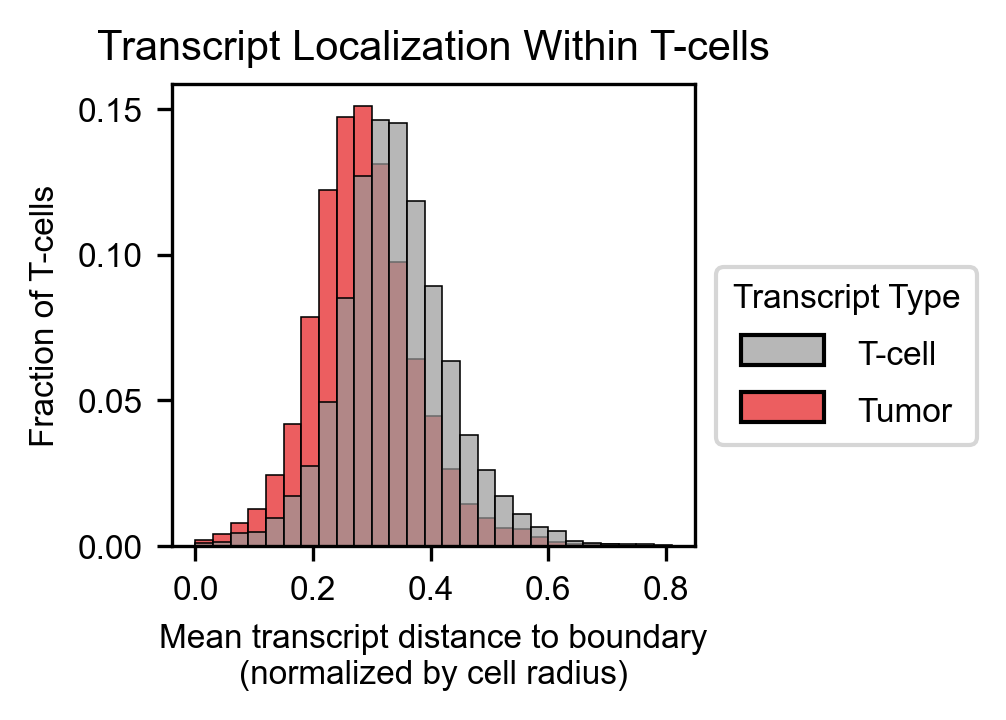

In [30]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl

# Path to where you saved the downloaded Arial file
font_path = '/home/jwinchel/fonts/ARIAL.TTF'  
fm.fontManager.addfont(font_path)
mpl.rcParams['svg.fonttype'] = 'none'
# Set Arial globally
plt.rcParams['font.family'] = 'Arial'
REPO = Path('/home/jwinchel/Syndri')
FIGURE_DIR = REPO / 'figures' / 'outputs'
# Exclude out-of-polygon transcripts from the primary summary, while preserving
# them in transcript_distances and reporting their frequency in cell_qc.
inside_distances = transcript_distances.loc[
    transcript_distances["inside_cell_polygon"]
].copy()

cell_distances = (
    inside_distances.groupby(
        ["slice_id", "cell_id", "gene_annot"], as_index=False, observed=True
    )
    .agg(
        mean_normalized_distance=("normalized_distance", "mean"),
        median_normalized_distance=("normalized_distance", "median"),
        mean_distance_to_boundary=("distance_to_boundary", "mean"),
        n_transcripts=("feature_name", "size"),
    )
)
cell_distances['Transcript Type'] = cell_distances['gene_annot'].map({'t-cell marker':'T-cell','tumor marker':'Tumor'})
cell_distances.to_csv(OUTPUT_DIR / "cell_distance_summaries.csv", index=False)
red_gray_colors = ["#999999", "#E41A1C"]  # Gray, Red
palette = sns.color_palette(red_gray_colors)
fig, ax = plt.subplots(figsize=(2.25, 2), dpi=300)
ax = sns.histplot(
    data=cell_distances,
    x="mean_normalized_distance",
    hue="Transcript Type",
    ax=ax,
    stat='proportion',
    common_norm=False,
    palette=palette,
    bins=np.arange(0,0.91,0.03),
    alpha=0.7,
)
ax.set_xlim([-0.04,0.85])
# handles, labels = ax.get_legend_handles_labels()

# fig.legend(loc='center right')
ax.set(
    title=f"Transcript Localization Within T-cells",
    xlabel="Mean transcript distance to boundary\n(normalized by cell radius)",
    ylabel="Fraction of T-cells",
)
ax.set_title(f"Transcript Localization Within T-cells",fontsize=10)
ax.tick_params(axis='both', which='major', labelsize=8)
ax.set_xlabel("Mean transcript distance to boundary\n(normalized by cell radius)",fontsize=8)
ax.set_ylabel("Fraction of T-cells",fontsize=8)
leg = ax.get_legend()
leg.set_label(leg.get_label())
leg.set_bbox_to_anchor((1, 0.65))
leg.set_loc("upper left")
for text in leg.get_texts():
    text.set_fontsize(8)
# fig.tight_layout()
# fig.savefig(OUTPUT_DIR / "normalized_boundary_distance_histplot.png", bbox_inches="tight")
# plt.show()
leg.get_title().set_fontsize(8)

fig.savefig(
    FIGURE_DIR / 'Figure1_localization.svg',
    bbox_inches='tight',
)

display(
    cell_distances.groupby("gene_annot")["mean_normalized_distance"]
    .describe()
    .round(3)
)

## Transcript counts and category proportions per sampled cell

Counts include all marker transcripts assigned to each sampled cell. The
tumor fraction uses **all assigned transcripts** in that cell as its
denominator, including transcripts outside the two marker sets. Cells with
no assigned transcripts retain zero marker counts and an undefined (`NaN`) fraction.

/tmp/ipykernel_2896879/202302946.py:76: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(),fontsize=8)
/tmp/ipykernel_2896879/202302946.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),fontsize=8)


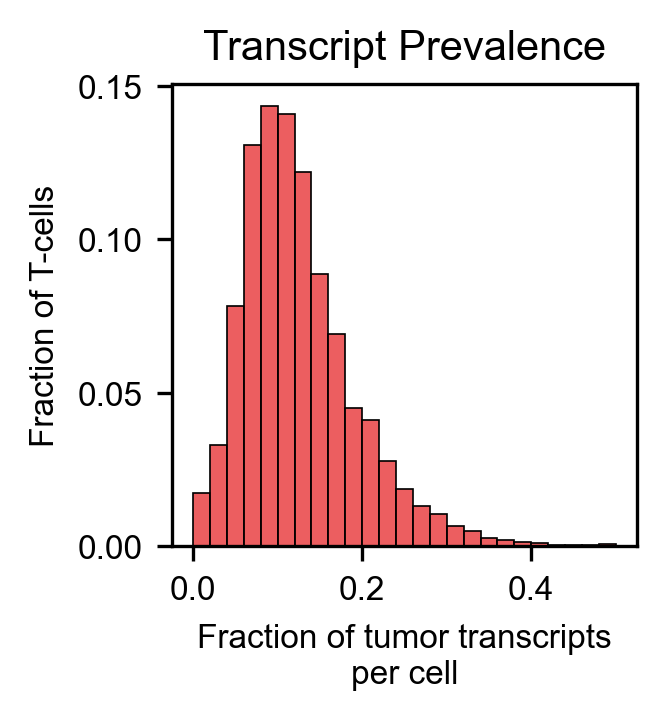

,total_transcripts,mean_transcripts_per_cell,median_transcripts_per_cell,mean_proportion,median_proportion
gene_annot,,,,,
t-cell marker,280679,28.068,24.0,0.288,0.286
tumor marker,123953,12.395,9.0,0.125,0.113


(80,)

In [36]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl

# Path to where you saved the downloaded Arial file
font_path = '/home/jwinchel/fonts/ARIAL.TTF'  
fm.fontManager.addfont(font_path)
mpl.rcParams['svg.fonttype'] = 'none'
# Set Arial globally
plt.rcParams['font.family'] = 'Arial'
REPO = Path('/home/jwinchel/Syndri')
FIGURE_DIR = REPO / 'figures' / 'outputs'
marker_categories = pd.DataFrame({
    "gene_annot": ["t-cell marker", "tumor marker"]
})

# Create both category rows for every sampled cell before joining observed
# counts, so a missing category is represented by zero rather than omitted.
cell_category_grid = sampled_cells[["slice_id", "cell_id"]].merge(
    marker_categories, how="cross"
)
observed_counts = pd.concat(marker_count_frames, ignore_index=True)[
    ["slice_id", "cell_id", "gene_annot", "n_transcripts"]
]


cell_transcript_composition = cell_category_grid.merge(
    observed_counts,
    on=["slice_id", "cell_id", "gene_annot"],
    how="left",
)
cell_transcript_composition["n_transcripts"] = (
    cell_transcript_composition["n_transcripts"].fillna(0).astype(int)
)
total_counts = pd.concat(total_count_frames, ignore_index=True)
cell_transcript_composition = cell_transcript_composition.merge(
    total_counts, on=["slice_id", "cell_id"], how="left", validate="many_to_one"
)
cell_transcript_composition["total_transcripts"] = (
    cell_transcript_composition["total_transcripts"].fillna(0).astype(int)
)
assert (cell_transcript_composition["n_transcripts"] <= cell_transcript_composition["total_transcripts"]).all()
cell_transcript_composition["transcript_proportion"] = (
    cell_transcript_composition["n_transcripts"]
    .div(cell_transcript_composition["total_transcripts"].replace(0, np.nan))
)

assert len(cell_transcript_composition) == 2 * len(sampled_cells)
cell_transcript_composition.to_csv(
    OUTPUT_DIR / "cell_transcript_composition.csv", index=False
)
# red_gray_colors = ["#999999", "#E41A1C"]  # Gray, Red
palette = sns.color_palette(red_gray_colors)
fig, ax = plt.subplots(figsize=(2, 2), dpi=300)
sns.histplot(
    data=cell_transcript_composition[cell_transcript_composition['gene_annot']=='tumor marker'],
    x="transcript_proportion",
    stat='proportion',
    ax=ax,
    color="#E41A1C",
    # palette=palette,
    bins=np.arange(0,0.51,0.02),
    alpha=0.7
)
ax.set(
    title="Transcript Prevalence",
    xlabel="Fraction of tumor transcripts\nper cell",
    ylabel="Fraction of T-cells",
)
ax.set_yticklabels(ax.get_yticklabels(),fontsize=8)
ax.set_ylabel(ax.get_ylabel(),fontsize=8)
ax.set_xticklabels(ax.get_xticklabels(),fontsize=8)
ax.set_xlabel(ax.get_xlabel(),fontsize=8)
ax.set_title("Transcript Prevalence",fontsize=10)
# fig.tight_layout()
fig.savefig(
    FIGURE_DIR / 'Figure1_prevalence.svg',
    bbox_inches='tight',
)
# fig.savefig(OUTPUT_DIR / "tumor_transcript_fraction_histogram.png", bbox_inches="tight")
plt.show()

display(
    cell_transcript_composition.groupby("gene_annot")
    .agg(
        total_transcripts=("n_transcripts", "sum"),
        mean_transcripts_per_cell=("n_transcripts", "mean"),
        median_transcripts_per_cell=("n_transcripts", "median"),
        mean_proportion=("transcript_proportion", "mean"),
        median_proportion=("transcript_proportion", "median"),
    )
    .round(3)
)
cell_ids = cell_transcript_composition[(cell_transcript_composition['gene_annot']=='t-cell marker')&(cell_transcript_composition['n_transcripts']==0)]['cell_id']
cell_transcript_composition[(cell_transcript_composition['gene_annot']=='tumor marker')&(cell_transcript_composition['cell_id'].isin(cell_ids))]['cell_id'].unique().shape

## Output files

- `sampled_tcells.csv`: the reproducible 500-cell sample
- `transcript_boundary_distances.parquet`: transcript-level raw and normalized distances
- `cell_distance_summaries.csv`: per-cell/per-marker-category summaries
- `cell_qc.csv`: polygon, transcript, and containment diagnostics for all sampled cells
- `cell_transcript_composition.csv`: per-cell counts and proportions for both marker categories
- `normalized_boundary_distance_ecdf.png`: the summary plot